In [1]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
import PyComplexHeatmap as pch
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
# matplotlib.rcParams['font.family'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
from utils import get_nnmd, annotate_essentiality

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
TEMPDIR = Path(config['TEMPDIR'])
cell_line_dict=config['cell_lines']
cell_lines = list(cell_line_dict.values())

In [2]:
# Load DepMap data
df = pd.read_csv("/scratch/peidli/DepMap/depmap_export_2024-06-13 08_40_33.976743_subsetted_NAsdropped.csv", index_col=1)
df = df.loc[:, (~df.isna()).sum(0) != 0]  # remove all-nan columns
# df = df.drop('depmap_id', axis=1)
df.index = df.index.str.replace("NCI", "")

In [3]:
# Define Feature Types
columns = df.columns
lineage = columns.str.startswith("lineage")
aneu = columns.str.startswith("Aneuploidy")
arm = columns.str.startswith("Arm-level CNAs")
cn = columns.str.startswith("Copy Number (Absolute)")
cnp = columns.str.startswith("Copy Number Public 24Q2")
crico = columns.str.startswith("CRISPR confounders")
bcexp = columns.str.startswith("Batch corrected Expression Public 24Q2")
exp = columns.str.startswith("Expression Public 24Q2")
cri_chronos = columns.str.startswith("CRISPR (DepMap Public 24Q2+Score, Chronos)")
cri_ps_ceres = columns.str.startswith("CRISPR (Project Score, CERES)")
cri_ps_chronos = columns.str.startswith("CRISPR (Project Score, Chronos)")
rnai_1 = columns.str.startswith("RNAi (Achilles+DRIVE+Marcotte, DEMETER2)")
rnai_2 = columns.str.startswith("RNAi (Achilles, DEMETER2)")
rnai_3 = columns.str.startswith("RNAi (DRIVE, DEMETER2)")

In [4]:
df.head()

,depmap_id,lineage_1,lineage_2,lineage_3,lineage_5,Aneuploidy Aneuploidy score,Aneuploidy Ploidy,Aneuploidy Genome doublings,Arm-level CNAs 1p,Arm-level CNAs 1q,...,"RNAi (DRIVE, DEMETER2) RBX1","RNAi (DRIVE, DEMETER2) CDC42","RNAi (DRIVE, DEMETER2) RCE1","RNAi (DRIVE, DEMETER2) HNRNPDL","RNAi (DRIVE, DEMETER2) DMTF1","RNAi (DRIVE, DEMETER2) PPP4R1","RNAi (DRIVE, DEMETER2) CDH1","RNAi (DRIVE, DEMETER2) PTBP3","RNAi (DRIVE, DEMETER2) KCNE2","RNAi (DRIVE, DEMETER2) CASP8AP2"
cell_line_display_name,,,,,,,,,,,,,,,,,,,,,
A549,ACH-000681,Lung,Non-Small Cell Lung Cancer,Lung Adenocarcinoma,NSCLC Adenocarcinoma,23.0,2.85,1.0,-1.0,0.0,...,-1.726331,0.009322,-0.025797,-0.100949,-0.006433,-0.028276,-0.055418,-0.414615,0.031194,-0.425915
H1299,ACH-000510,Lung,Non-Small Cell Lung Cancer,Large Cell Lung Carcinoma,NSCLC Large Cell,27.0,2.62,1.0,-1.0,-1.0,...,-1.827748,-0.905985,0.017159,-0.066058,-0.088608,-0.116749,-0.005625,-0.112230,0.039325,-0.438915
H1975,ACH-000587,Lung,Non-Small Cell Lung Cancer,Lung Adenocarcinoma,NSCLC Adenocarcinoma,23.0,2.90,1.0,-1.0,0.0,...,-2.893821,-0.436538,0.255794,-0.556015,0.159989,0.176906,0.092378,-0.102944,-0.003241,-0.841914


In [5]:
# Load our data (MAGeCK scores)
tab = pd.read_csv('../results/merged/gene_results_perline.csv', index_col=0, header=[0, 1])
tab = tab.loc[:, (slice(None), 'MAGeCK_filtered_score')]
tab.columns = tab.columns.droplevel(1)
tab = tab.T
# tab.columns = 'SYMPHONY_' + tab.columns

In [6]:
# mtab = pd.merge(tab, df, left_index=True, right_index=True, how='inner')

# ROCs and NNMDs

In [7]:
# Depmap Corrected Scores
df_ = df.loc[:, cri_chronos]
df_.columns = df_.columns.str.replace("CRISPR (DepMap Public 24Q2+Score, Chronos) ", "", regex=False)

# Without correction
unc_df = pd.read_csv('/scratch/peidli/DepMap/CRISPRGeneEffectUncorrected.csv', index_col=0)
inv_map = {v: k for k, v in df.depmap_id.to_dict().items()}
unc_df.index = unc_df.index.map(inv_map)
unc_df = unc_df.loc[df.index]  # take only our cell lines
unc_df.columns = unc_df.columns.str.split(' (', regex=False).str[0]

In [8]:
super_df = pd.concat({'SYMPHONY': tab, 'DepMap Chronos': df_, 'DepMap uncorrected': unc_df}, axis=1, join='inner')

In [83]:
# essential genes
essential = pd.read_csv("../resources/bagel_supplement/CEGv2.txt", sep='\t', index_col=0)
non_essential = pd.read_csv("../resources/bagel_supplement/NEGv1.txt", sep='\t', index_col=0)

# Common genes
gene_overlap = list(set(tab.columns) & set(df_.columns))

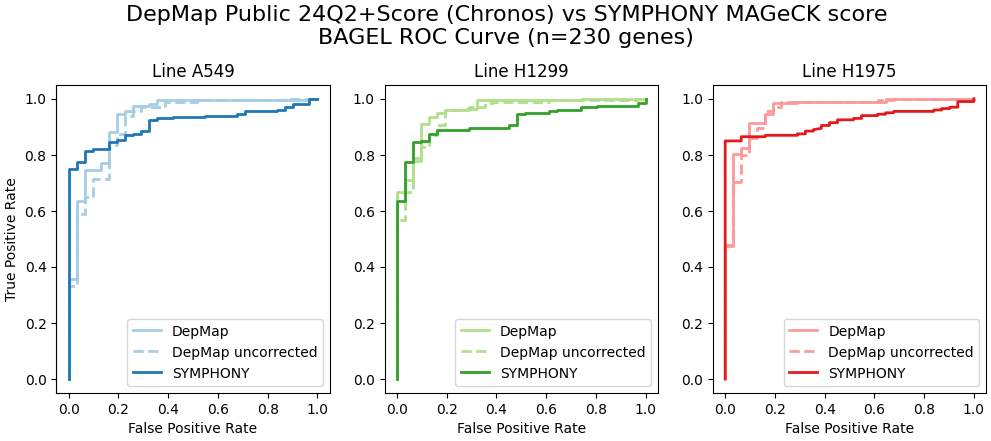

In [102]:
from sklearn.metrics import roc_curve
from matplotlib.cm import get_cmap

fig, axs = pl.subplots(1, 3, figsize=(4*3,4))
cmap = get_cmap('Paired')

i = 0
for ax, line in zip(axs, ['A549', 'H1299', 'H1975']):
    # DepMap
    sdf = super_df.loc[[line], 'DepMap Chronos'].T
    sdf.columns = ['score']
    sdf['essentiality'] = annotate_essentiality(sdf.index)
    mask = (sdf.essentiality!='unknown') & (sdf.index.isin(gene_overlap))
    fpr, tpr, thresholds = roc_curve(sdf[mask].essentiality=='essential', -sdf[mask].score)
    style ='-'
    color = cmap(i)
    ax.plot(fpr, tpr, label="DepMap", linewidth=2, linestyle=style, color=color)
    
    # DepMap uncorrected
    sdf = super_df.loc[[line], 'DepMap uncorrected'].T
    sdf.columns = ['score']
    sdf['essentiality'] = annotate_essentiality(sdf.index)
    mask = (sdf.essentiality!='unknown') & (sdf.index.isin(gene_overlap))
    fpr, tpr, thresholds = roc_curve(sdf[mask].essentiality=='essential', -sdf[mask].score)
    style ='--'
    color = cmap(i)
    ax.plot(fpr, tpr, label="DepMap uncorrected", linewidth=2, linestyle=style, color=color)
    i += 1
    
    # SYMPHONY
    sdf = super_df.loc[[line], 'SYMPHONY'].T
    sdf.columns = ['score']
    sdf['essentiality'] = annotate_essentiality(sdf.index)
    mask = (sdf.essentiality!='unknown') & (sdf.index.isin(gene_overlap))
    fpr, tpr, thresholds = roc_curve(sdf[mask].essentiality=='essential', -sdf[mask].score)
    style ='-'
    color = cmap(i)
    ax.plot(fpr, tpr, label="SYMPHONY", linewidth=2, linestyle=style, color=color)
    i += 1
    
    ax.legend()
    ax.set_xlabel('False Positive Rate')
    if ax == axs[0]: ax.set_ylabel('True Positive Rate')
    ax.set_title(f'Line {line}')
pl.suptitle(f'DepMap Public 24Q2+Score (Chronos) vs SYMPHONY MAGeCK score\nBAGEL ROC Curve (n={(mask).sum()} genes)', y=1.08, fontsize=16)
# pl.savefig(f'../results/bagel2/bagel2_roc{name}.pdf', bbox_inches='tight', dpi=300)
pl.show()


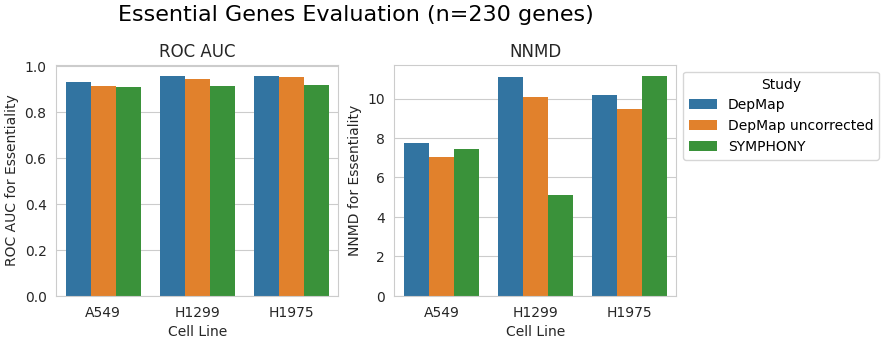

In [85]:
# AUC scores
from sklearn.metrics import roc_auc_score
aucs = {}
nnmds = {}
for line in ['A549', 'H1299', 'H1975']:
    # DepMap
    sdf = super_df.loc[[line], 'DepMap Chronos'].T
    sdf.columns = ['score']
    sdf['essentiality'] = annotate_essentiality(sdf.index)
    mask = (sdf.essentiality!='unknown') & (sdf.index.isin(gene_overlap))
    aucs[(line, 'DepMap')] = roc_auc_score(sdf[mask].essentiality=='essential', -sdf[mask].score)
    nnmds[(line, 'DepMap')] = get_nnmd(sdf, score_column='score')
    
    # DepMap
    sdf = super_df.loc[[line], 'DepMap uncorrected'].T
    sdf.columns = ['score']
    sdf['essentiality'] = annotate_essentiality(sdf.index)
    mask = (sdf.essentiality!='unknown') & (sdf.index.isin(gene_overlap))
    aucs[(line, 'DepMap uncorrected')] = roc_auc_score(sdf[mask].essentiality=='essential', -sdf[mask].score)
    nnmds[(line, 'DepMap uncorrected')] = get_nnmd(sdf, score_column='score')
    
    # SYMPHONY
    sdf = super_df.loc[[line], 'SYMPHONY'].T
    sdf.columns = ['score']
    sdf['essentiality'] = annotate_essentiality(sdf.index)
    mask = (sdf.essentiality!='unknown') & (sdf.index.isin(gene_overlap))
    aucs[(line, 'SYMPHONY')] = roc_auc_score(sdf[mask].essentiality=='essential', -sdf[mask].score)
    nnmds[(line, 'SYMPHONY')] = get_nnmd(sdf, score_column='score')
auc_df = pd.DataFrame(aucs, index=['AUC']).T.reset_index().rename(columns={'level_0':'line', 'level_1':'origin'})
nnmd_df = pd.DataFrame(nnmds, index=['NNMD']).T.reset_index().rename(columns={'level_0':'line', 'level_1':'origin'})

with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 2, figsize=(4*2,3), gridspec_kw=dict(hspace=0.7))
ax = axs[0]
sns.barplot(data=auc_df, x='line', y='AUC', hue='origin', ax=ax)
ax.legend_.remove()
ax.set_xlabel('Cell Line')
ax.set_ylabel('ROC AUC for Essentiality')
ax.set_title('ROC AUC')

ax = axs[1]
sns.barplot(data=nnmd_df, x='line', y='NNMD', hue='origin', ax=ax)
ax.set_xlabel('Cell Line')
ax.set_ylabel('NNMD for Essentiality')
ax.set_title('NNMD')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), title='Study')

pl.suptitle(f'Essential Genes Evaluation (n={mask.sum()} genes)', fontsize=16, y=1.08)

# pl.savefig(f'../results/bagel2/bagel2_eval{name}.pdf', bbox_inches='tight', dpi=300)
pl.show()

Text(0.5, 1.0, 'ROC AUC by Line and Screen')

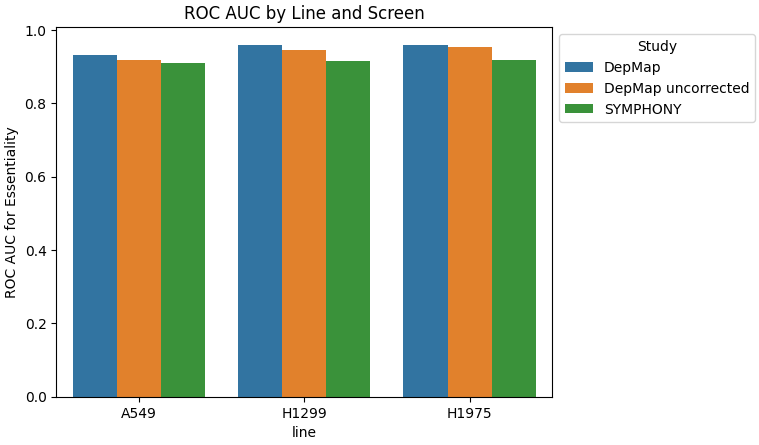

In [86]:
ax = sns.barplot(data=auc_df, x='line', y='AUC', hue='origin')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), title='Study')
pl.ylabel('ROC AUC for Essentiality')
pl.title('ROC AUC by Line and Screen')

# Which known non/ess genes are most different? Can we explain why they are different?

In [20]:
super_df_ = pd.concat({'SYMPHONY': tab, 'DepMap Chronos': df_, 'DepMap uncorrected': unc_df}, axis=0, join='inner').T
super_df_['essentiality'] = annotate_essentiality(super_df_.index)
ddr_genes = pd.read_csv('../resources/HALLMARK_DNA_REPAIR.v2023.2.Hs.tsv', sep='\t', index_col=0).loc['GENE_SYMBOLS'][0].split(',')
super_df_['ddr'] = super_df_.index.isin(ddr_genes)

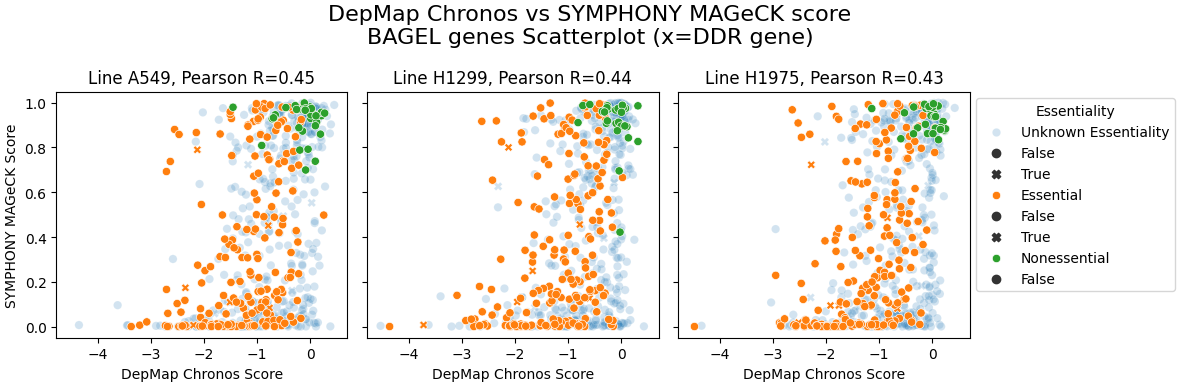

In [29]:
fig, axs = pl.subplots(1, 3, figsize=(4*3,4), sharex=True, sharey=True)
for line, ax in zip(['A549', 'H1299', 'H1975'], axs):
    y = ('SYMPHONY', line)
    x = ('DepMap Chronos', line)
    sns.scatterplot(data=super_df_[super_df_.essentiality == 'unknown'], 
                    x=x, y=y, ax=ax, style='ddr',
                    label='Unknown Essentiality', alpha=0.2)
    sns.scatterplot(data=super_df_[super_df_.essentiality == 'essential'], 
                    x=x, y=y, ax=ax, style='ddr',
                    label='Essential')
    sns.scatterplot(data=super_df_[super_df_.essentiality == 'non-essential'], 
                    x=x, y=y, ax=ax, style='ddr',
                    label='Nonessential')
    # peason correlation
    from scipy.stats import pearsonr
    r, p = pearsonr(super_df_[x], super_df_[y])
    ax.set_title(f'Line {line}, Pearson R={r:.2f}')
    ax.set_ylabel('SYMPHONY MAGeCK Score')
    ax.set_xlabel('DepMap Chronos Score')
    
    # Legend placement
    if ax == axs[-1]:
        sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), title='Essentiality')
    else:
        ax.legend_.remove()
pl.suptitle('DepMap Chronos vs SYMPHONY MAGeCK score\nBAGEL genes Scatterplot (x=DDR gene)', fontsize=16)
pl.tight_layout()
pl.show()

I can't seem to find strong outliers here.

In [174]:
line = 'A549'
tdf = super_df_.loc[:, [('SYMPHONY', line), ('DepMap Chronos', line)]]
tdf.columns = tdf.columns.droplevel(1)
genes = list(tdf[(tdf['SYMPHONY']>0.9) & (tdf['DepMap Chronos']<-1)].index)  # non-essential in SYMPHONY, essential in DepMap

In [175]:
import gseapy as gp
enr = gp.enrichr(gene_list=genes, # or "./tests/data/gene_list.txt",
                 gene_sets=['MSigDB_Hallmark_2020','KEGG_2021_Human'],
                 background=super_df_.index,  # all tested genes
                 organism='human',
                 outdir=None, # don't write to disk
                )
res = enr.results
res = res[res['Adjusted P-value']<0.05]
res.head(20)


,Gene_set,Term,P-value,Adjusted P-value,Old P-value,Old adjusted P-value,Odds Ratio,Combined Score,Genes
